# NN_L10_trading_learning

**PPO actor-critic agent trading the S&P 500 (flat or long, 5 bp cost): Sharpe ratio on training and validation years during training.**

Neural Networks and Deep Learning (NN), Lecture 10 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L10/NN_L10_trading_learning/NN_L10_trading_learning.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

buy-and-hold Sharpe 2017-2019 = 0.95   [trade.bh_valid_sharpe]


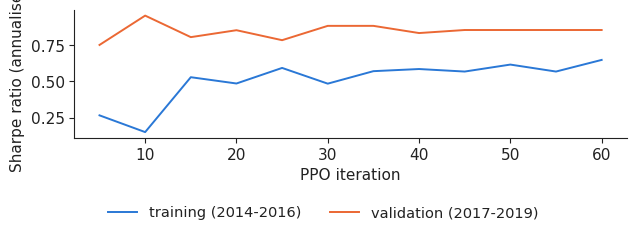

In [3]:
import torch, torch.nn as nn
m = pd.read_csv(DATA + 'markets_daily.csv', parse_dates=['date'])
w = m.pivot(index='date', columns='ticker', values='close').loc[:'2026-10-31']
px = w['SP500'].dropna(); vix = w['VIX'].reindex(px.index).ffill()
lr_ = np.log(px).diff()
F = pd.DataFrame({'r1': lr_, 'r5': np.log(px).diff(5), 'r21': np.log(px).diff(21), 'r63': np.log(px).diff(63),
                  'rv21': lr_.rolling(21).std() * np.sqrt(252), 'vix': vix / 100, 'ma200': px / px.rolling(200).mean() - 1}).dropna()
fwd = lr_.shift(-1).reindex(F.index); F, fwd = F.iloc[:-1], fwd.iloc[:-1]
tr_m, va_m, te_m = F.index.year <= 2016, (F.index.year >= 2017) & (F.index.year <= 2019), F.index.year >= 2020
X = ((F - F[tr_m].mean()) / F[tr_m].std()).values.astype(np.float32); RET = fwd.values.astype(np.float32); COST = 0.0005
def perf(pos, ret):
    pos = np.asarray(pos, float); return pos * ret - COST * np.abs(np.diff(np.concatenate([[0.0], pos])))
def stats_of(x):
    eq = np.exp(np.cumsum(x)); dd = eq / np.maximum.accumulate(eq) - 1
    return {'ann_ret': 100 * (np.exp(x.mean() * 252) - 1), 'ann_vol': 100 * x.std() * np.sqrt(252),
            'sharpe': x.mean() / x.std() * np.sqrt(252), 'maxdd': 100 * dd.min()}
ite, iva, itr = np.where(te_m)[0], np.where(va_m)[0], np.where(tr_m)[0]
bh = perf(np.ones(len(ite)), RET[ite]); ma_pos = (F['ma200'].values[ite] > 0).astype(float); ma = perf(ma_pos, RET[ite])
class AC(nn.Module):
    def __init__(s, d):
        super().__init__(); s.body = nn.Sequential(nn.Linear(d, 64), nn.Tanh(), nn.Linear(64, 64), nn.Tanh())
        s.pi = nn.Linear(64, 2); s.v = nn.Linear(64, 1)
    def forward(s, x):
        h = s.body(x); return s.pi(h), s.v(h).squeeze(-1)
def run_policy(net, idx):
    pos, prev = [], 0.0
    with torch.no_grad():
        for i in idx:
            a = int(net(torch.from_numpy(np.append(X[i], prev).astype(np.float32)))[0].argmax()); pos.append(float(a)); prev = float(a)
    return np.array(pos)
def ppo(seed, iters=60, B=64, T=126):
    torch.manual_seed(seed); rng = np.random.default_rng(seed); net = AC(X.shape[1] + 1)
    opt = torch.optim.Adam(net.parameters(), lr=3e-4); hist, best = [], (-np.inf, None)
    for it in range(iters):
        st = rng.choice(itr[:-T], B); prev = np.zeros(B, np.float32); O, A_, LP, R_, V_ = [], [], [], [], []
        with torch.no_grad():
            for t in range(T):
                o = torch.from_numpy(np.concatenate([X[st + t], prev[:, None]], 1).astype(np.float32)); lg, v = net(o)
                dist = torch.distributions.Categorical(logits=lg); a = dist.sample(); pos = a.numpy().astype(np.float32)
                R_.append(torch.from_numpy(100 * (pos * RET[st + t] - COST * np.abs(pos - prev))))
                O.append(o); A_.append(a); LP.append(dist.log_prob(a)); V_.append(v); prev = pos
            O, A_, LP, R_, V_ = map(torch.stack, (O, A_, LP, R_, V_)); adv = torch.zeros_like(R_); g = torch.zeros(B)
            for t in range(T - 1, -1, -1):
                vn = V_[t + 1] if t + 1 < T else torch.zeros(B); g = R_[t] + 0.99 * vn - V_[t] + 0.99 * 0.95 * g; adv[t] = g
            ret = adv + V_
        O, A_, LP, adv, ret = (z.reshape(T * B, *z.shape[2:]) for z in (O, A_, LP, adv, ret)); adv = (adv - adv.mean()) / (adv.std() + 1e-8)
        for _ in range(4):
            for b in torch.from_numpy(rng.permutation(T * B)).split(1024):
                lg, v = net(O[b]); dist = torch.distributions.Categorical(logits=lg); rho = torch.exp(dist.log_prob(A_[b]) - LP[b])
                loss = -torch.min(rho * adv[b], rho.clamp(0.8, 1.2) * adv[b]).mean() + 0.5 * ((v - ret[b]) ** 2).mean() - 0.01 * dist.entropy().mean()
                opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(net.parameters(), 0.5); opt.step()
        if it % 5 == 4:
            s_tr = stats_of(perf(run_policy(net, itr[-756:]), RET[itr[-756:]]))['sharpe']; s_va = stats_of(perf(run_policy(net, iva), RET[iva]))['sharpe']
            hist.append((it + 1, s_tr, s_va))
            if s_va > best[0]: best = (s_va, {k: v.clone() for k, v in net.state_dict().items()})
    net.load_state_dict(best[1]); return net, hist
net, hist = ppo(20261108)
H = np.array(hist)
show('trade.bh_valid_sharpe', 'buy-and-hold Sharpe 2017-2019', round(float(stats_of(perf(np.ones(len(iva)), RET[iva]))['sharpe']), 2))
fig, ax = plt.subplots(figsize=(6.4, 2.4))
ax.plot(H[:, 0], H[:, 1], color=PAL['train'], label='training (2014-2016)')
ax.plot(H[:, 0], H[:, 2], color=PAL['valid'], label='validation (2017-2019)')
ax.set_xlabel('PPO iteration'); ax.set_ylabel('Sharpe ratio (annualised)'); legend_bottom(fig, ncol=2); fig.tight_layout(rect=(0, 0.14, 1, 1))
fig.savefig('trading_learning.png', dpi=200, transparent=True, bbox_inches='tight'); plt.show()